<a href="https://colab.research.google.com/github/Emelygabrielaa/calgary-building-permits-eda/blob/main/notebooks/02_q2_project_cost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project: Calgary Building Permits, Descriptive Analysis and EDA**

**Path:** Statistician path, Project 1 of 11  
**Question:** 2 of 5, Project cost (How much are the projects worth?)  
**Author:** Emely Rodriguez  
**Languages:** Python (lead), R (cross-check in a separate notebook)  
**Data as of:** 2026-10-27 snapshot, processed dataset (502,814 rows, 46 columns).   
**Licence:** Contains information licensed under the Open Government Licence - City of Calgary.

## Project phases

| Phase | Content | Status |
|---|---|---|
| 0. Data audit | Structure, quality and definitions of the source data | Done |
| 1. Analysis dataset | Handling of audit issues, selected columns, derived variables, dated snapshot | Done |
| **2. Analysis** | **Part A (descriptive) and Part B (formal tests and models), one notebook per question** | **This notebook (Question 2)** |
| 3. Report | Findings and conclusions | Pending |

## What this project is about
The City of Calgary publishes its building permit application records, which start in June 1999. In this project I use that table to answer five practical questions: how long applications take, how much the projects are worth, how activity changes over time, where it happens, and how complete the data is. In each question's notebook, Part A answers it with descriptive statistics and Part B follows with formal tests and models.

## The five questions

| # | Topic | Question | Part A: descriptive | Part B: going deeper |
|---|---|---|---|---|
| 1 | Processing time | How long do applications take? | Days from application to issue, with percentiles by permit type | Kruskal-Wallis with pairwise tests, and Kaplan-Meier curves |
| **2** | **Project cost** | **How much are the projects worth?** | **Skewness, log scale, tail, and summaries by class** | **Lognormal fit check, bootstrap intervals for medians, quantile regression** |
| 3 | Volume over time | How does activity change over time? | Counts by year and month, seasonality plots | Decomposition, Mann-Kendall trend test, count regression |
| 4 | Geography | Where does it happen? | Counts and medians by community, and a map | Rates per community and Moran's I |
| 5 | Missingness | How complete is the data? | Missing rates by column and permit type | Chi-square tests and logistic regression of missingness |

This notebook covers Question 2 (in bold). The other questions are in their own notebooks.

## The data

* Source: City of Calgary Open Data portal, dataset "Building Permits" (ID c2es-76ed)
* Provider: The City of Calgary, Dev Business and Bldg Srvc
* What a row is: a building permit application record, identified by `permitnum` (unique, checked in section 0.2.1 of the Phase 0 notebook)
* Coverage: applications from 1999-06-22 onward, updated daily
* Size: about 503,000 rows and 30 columns in the portal. The processed dataset has 502,814 rows and 46 columns, built in Phase 1 from a snapshot of 21 columns.
* File used: `data/processed/building_permits_processed_2026-10-27.parquet` in the project repository (Phase 1)
* Coordinates: WGS84 (EPSG:4326), in degrees
* Licence: City of Calgary Open Data Terms (https://data.calgary.ca/d/Open-Data-Terms/u45n-7awa)

Reproducibility note: this notebook reads the processed dataset of Phase 1, which is fixed, so the results do not change between runs. The dataset comes from the portal snapshot of 2026-10-27. The handling decisions and the definitions of the variables are in the Phase 1 notebook.

## Pills for this project
**Board pills:** Descriptive/EDA, Group Comparison, Missing-data analysis, Trend analysis,
Regression analysis, Uncertainty analysis, Spatial

**Method pills:** percentiles, ecdf, skewness, log-transform, heavy-tails, kruskal-wallis,
multiple-comparisons, censoring, kaplan-meier, competing-risks, lognormal-fit, bootstrap, quantile-regression, seasonality,
decomposition, mann-kendall, count-regression, rates-per-area, morans-i, choropleth,
missing-rates, chi-square, logistic-regression, mar-vs-mcar

## Pills for this notebook
**Board pills:** Descriptive/EDA, Group Comparison, Trend analysis, Regression analysis, Uncertainty analysis

**Method pills:** percentiles, ecdf, skewness, log-transform, heavy-tails, lognormal-fit, bootstrap, quantile-regression

----------

# **Phase 2, Question 2: Project cost**

**Question:** how much are the projects worth?

**Goal:** describe the estimated project cost, its skewed distribution and how it differs by permit class and over the years (Part A), and then check a lognormal model, measure the uncertainty of the medians and model how the cost quantiles change with the characteristics of the permit (Part B).

**Input:** the processed dataset built in Phase 1. The handling decisions and the definitions of the variables are in the Phase 1 notebook, and this notebook does not repeat them.

## Q2.0 Setup

This notebook has its own setup, so it can run without the other notebooks.

### Q2.0.1 Libraries and data address

In [1]:
# Import the libraries: web requests, file handling, data tables, numbers and plots
import io, requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt

# Date of the snapshot the processed dataset was built from
SNAP_DATE = "2026-10-27"

# Address of the processed dataset in the public repository (raw file)
PROCESSED_URL = ("https://raw.githubusercontent.com/Emelygabrielaa/"
                 "calgary-building-permits-eda/main/data/processed/"
                 f"building_permits_processed_{SNAP_DATE}.parquet")

### Q2.0.2 Loading the processed dataset

In [2]:
# Download the processed dataset and read it as a table
r = requests.get(PROCESSED_URL, timeout=300)
r.raise_for_status()                                   # stop with an error if the download fails
df = pd.read_parquet(io.BytesIO(r.content))

# Check the size: it must be 502,814 rows and 46 columns
print(df.shape)
print("Unique permit numbers:", df["permitnum"].nunique())

(502814, 46)
Unique permit numbers: 502814


The table has 502,814 rows and 46 columns, and every permit number is unique.

# **Part A: Descriptive analysis**

| Section | Topic | What it shows |
|---|---|---|
| Q2.1 | What is measured | The cost column, its cleaning rules and the missing values |
| Q2.2 | Overall distribution | Percentiles, skewness and the shape on the log scale |
| Q2.3 | Extreme values | The largest projects and the share of the total value they hold |
| Q2.4 | Cost by class | Percentiles by group and the comparison on the log scale |
| Q2.5 | Cost over the years | Median and total value by year, in current dollars |
| Q2.6 | Applications without cost | Who has a missing cost, by group and by period |
| Summary | Summary of Part A | What the descriptive analysis shows |

## Q2.1 What is measured

The cost is `estprojectcost_clean`, the estimated project cost in dollars. Phase 1 keeps the original value in `estprojectcost` and sets to missing the values that cannot be a real cost (negative values and values below 10 dollars), with the reason in the flag `cost_issue`.


In [3]:
# Cost columns: original value, cleaned value and the flag with the reason
cols = ["estprojectcost", "estprojectcost_clean", "cost_issue"]
print(df[cols].dtypes.to_string(), "\n")

# Applications in each value of the flag
print(df["cost_issue"].value_counts(dropna=False).to_string(), "\n")

# Missing values in the original and in the cleaned cost
print("Missing in the original cost:", df["estprojectcost"].isna().sum())
print("Missing in the cleaned cost:", df["estprojectcost_clean"].isna().sum())

estprojectcost          float64
estprojectcost_clean    float64
cost_issue               object 

cost_issue
none        502297
below 10       509
negative         8 

Missing in the original cost: 39023
Missing in the cleaned cost: 39540


The original cost is missing in 39,023 applications. The cleaning adds 517 more: 509 values below 10 dollars and 8 negative values. The cleaned cost is missing in 39,540 applications (7.9%) and has a value in 463,274.

## Q2.2 Overall distribution

In [4]:
# Projects with a cost (the cleaned cost without missing values)
c = df["estprojectcost_clean"].dropna()

# Summary: count, mean, minimum, maximum and skewness
print("Projects with cost:", f"{len(c):,}")
print("Mean:", f"{c.mean():,.0f}")
print("Minimum:", f"{c.min():,.0f}", "| Maximum:", f"{c.max():,.0f}")
print("Skewness:", round(c.skew(), 1), "\n")

# Percentiles of the cost
pct = c.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
print(pct.apply(lambda v: f"{v:,.0f}").to_string())

Projects with cost: 463,274
Mean: 273,660
Minimum: 10 | Maximum: 868,255,213
Skewness: 116.6 

0.010           900
0.050         2,500
0.250        15,778
0.500        55,549
0.750       200,000
0.900       370,476
0.950       515,146
0.990     2,351,670
0.999    25,366,829


Half of the projects cost less than 55,549 dollars, while the mean is 273,660, almost five times higher. The skewness of 116.6 confirms a very long right tail: 75% of the projects cost 200,000 dollars or less and 99% cost less than 2.35 million, but the largest project is 868 million. The top 0.1% starts at 25.4 million. A few very large projects pull the mean, so the median and the percentiles describe the typical project better than the mean.

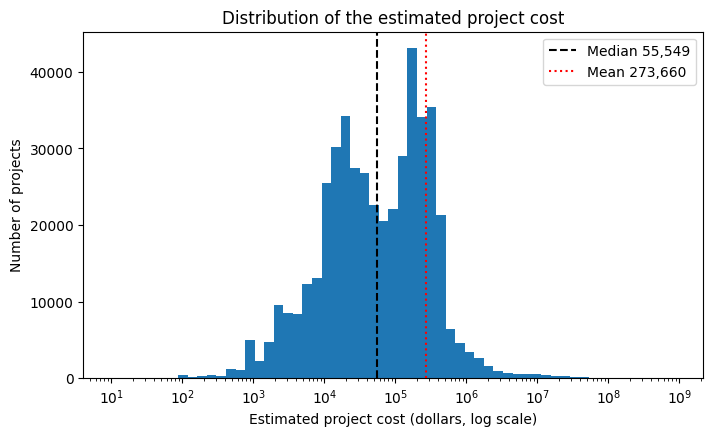

In [5]:
# Histogram of the cost on a log scale: each bin covers the same ratio between its limits
bins = np.logspace(1, np.log10(c.max()), 60)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(c, bins=bins)
ax.set_xscale("log")

# Median and mean as vertical lines
ax.axvline(c.median(), color="black", linestyle="--", label=f"Median {c.median():,.0f}")
ax.axvline(c.mean(), color="red", linestyle=":", label=f"Mean {c.mean():,.0f}")

ax.set_xlabel("Estimated project cost (dollars, log scale)")
ax.set_ylabel("Number of projects")
ax.set_title("Distribution of the estimated project cost")
ax.legend()
plt.show()

On the log scale the distribution has two peaks, one near 20,000 dollars and one near 150,000, and the median (55,549) falls in the valley between them. This suggests two groups of projects of different size mixed in the same column, which Q2.4 checks by permit group. There is also a small spike near 1,000 dollars, and the mean sits on the right peak because the tail above 1 million pulls it up. A single bell shape on the log scale would not describe these data well, which matters for the lognormal check in Part B.

### Q2.2.1 Repeated values

In [6]:
# The ten most repeated cost values, with their share of the projects that have a cost
top = c.value_counts().head(10)
table = pd.DataFrame({"projects": top, "share (%)": (top / len(c) * 100).round(1)})
table.index = [f"{v:,.0f}" for v in table.index]
print(table.to_string())

# Share of projects whose cost is a multiple of 1,000 and of 10,000
print("\nMultiple of 1,000:", round((c % 1000 == 0).mean() * 100, 1), "%")
print("Multiple of 10,000:", round((c % 10000 == 0).mean() * 100, 1), "%")

        projects  share (%)
10,000      4147        0.9
5,000       3955        0.9
38,576      3710        0.8
20,000      3657        0.8
1,000       3520        0.8
42,434      3508        0.8
50,000      3168        0.7
15,000      3055        0.7
30,000      3034        0.7
2,000       2864        0.6

Multiple of 1,000: 20.3 %
Multiple of 10,000: 9.8 %


The most repeated costs are round amounts (10,000, 5,000, 20,000, 1,000, 50,000 and others), and two odd values, 38,576 and 42,434, each appear more than 3,500 times. The ten most repeated values hold 7.5% of the projects. One in five costs (20.3%) is a multiple of 1,000 and one in ten (9.8%) is a multiple of 10,000, far above the 0.1% and 0.01% that chance would give. Many estimated costs are declared as round figures, and the two odd repeated values need an explanation.

In [7]:
# The two odd repeated values, taken exactly as they are in the table (the second one has cents)
odd = top.index[[2, 5]]

for v in odd:
    s = df[df["estprojectcost_clean"] == v]
    print(f"Cost {v:,.2f}: {len(s):,} projects")
    print(s["permittype"].value_counts().head(3).to_string())
    print(s["permitclassmapped"].value_counts().head(3).to_string())
    print("Application years:", int(s["application_year"].min()), "to", int(s["application_year"].max()),
          "| median", int(s["application_year"].median()), "\n")

Cost 38,576.00: 3,710 projects
permittype
Residential Improvement Project    3710
permitclassmapped
Residential    3710
Application years: 2019 to 2026 | median 2023 

Cost 42,433.60: 3,508 projects
permittype
Residential Improvement Project    3508
permitclassmapped
Residential    3508
Application years: 2019 to 2026 | median 2023 



Both odd values belong only to Residential Improvement applications from 2019 to 2026: 3,710 projects with a cost of 38,576 and 3,508 with 42,433.60. The second value is exactly 10% above the first (38,576 × 1.1), so they look like a fixed amount applied to many applications and later updated, not an estimate made for each project. Together they hold 7,218 projects, 1.6% of the projects with a cost. The data do not say how this value is set.

In [8]:
# Application years and work class of each of the two fixed values
for v in odd:
    s = df[df["estprojectcost_clean"] == v]
    print(f"Cost {v:,.2f}")
    print(s["application_year"].dropna().astype(int).value_counts().sort_index().to_string())
    print(s["workclassmapped_clean"].value_counts(dropna=False).head(5).to_string(), "\n")

Cost 38,576.00
application_year
2019    233
2020    282
2021    442
2022    539
2023    520
2024    577
2025    573
2026    544
workclassmapped_clean
New         3704
Existing       6 

Cost 42,433.60
application_year
2019    290
2020    338
2021    373
2022    447
2023    407
2024    559
2025    602
2026    492
workclassmapped_clean
New         3501
Existing       7 



Both odd values belong only to Residential Improvement applications from 2019 to 2026: 3,710 projects with a cost of 38,576 and 3,508 with 42,433.60. The second value is exactly 10% above the first (38,576 × 1.1), and both appear in every year, so they look like two fixed amounts used side by side, not an estimate made for each project. Almost all of them (99.8%) are classified as new work. Together they hold 7,218 projects, 1.6% of the projects with a cost. The data do not say how these values are set.

In [9]:
# Original permit class and work class of each of the two fixed values
for v in odd:
    s = df[df["estprojectcost_clean"] == v]
    print(f"Cost {v:,.2f}")
    print(s["permitclass"].value_counts().head(5).to_string())
    print(s["workclass"].value_counts().head(5).to_string(), "\n")

Cost 38,576.00
permitclass
1301 - Private Detached Garage    3710
workclass
New           3704
Addition         4
Alteration       2 

Cost 42,433.60
permitclass
1301 - Private Detached Garage    3508
workclass
New           3501
Alteration       4
Addition         3 



Both fixed amounts belong to one permit class, 1301 - Private Detached Garage, and almost all are new work. A new detached garage is therefore recorded with one of two standard amounts (38,576 or 42,433.60) in more than 7,000 applications. The data do not say why, but it shows that for this class the cost is not an estimate made for each project.

## Q2.3 Extreme values

In [10]:
# The ten largest projects, with the columns that describe them
cols = ["permitnum", "application_year", "permittype", "permitclass", "workclass", "estprojectcost_clean"]
largest = df.nlargest(10, "estprojectcost_clean")[cols].copy()
largest["estprojectcost_clean"] = largest["estprojectcost_clean"].map("{:,.0f}".format)
print(largest.to_string(index=False))

   permitnum  application_year                        permittype                permitclass workclass estprojectcost_clean
BP2017-12385              2017 Commercial / Multi Family Project            5201 - Hospital       New          868,255,213
BP2007-07297              2007 Commercial / Multi Family Project              3402 - Office       New          644,689,500
BP2024-24370              2024 Commercial / Multi Family Project               3502 - Arena       New          639,048,958
BP2011-00001              2011 Commercial / Multi Family Project        2308 - Terminal-Air  Addition          596,614,379
BP2021-09865              2021 Commercial / Multi Family Project           3203 - Warehouse       New          400,000,000
BP2013-10778              2013 Commercial / Multi Family Project              3402 - Office       New          376,000,000
BP2009-04369              2009 Commercial / Multi Family Project            5201 - Hospital       New          371,926,500
BP2007-15415    

The ten largest projects are all Commercial / Multi Family, between 315 and 868 million dollars: hospitals, offices, an arena, an air terminal, a warehouse and a recreation facility. They look like real large projects, not data entry errors, so no upper limit is applied in the cleaning. Several are round figures (400,000,000, 376,000,000, 320,000,000, 315,000,000), which agrees with the rounding seen in Q2.2.1.

In [11]:
# Share of the total value held by the largest projects
sorted_c = c.sort_values(ascending=False)
total = sorted_c.sum()
print(f"Total value of the projects with a cost: {total / 1e9:,.1f} billion dollars\n")

rows = []
for share in [0.001, 0.01, 0.1, 0.5]:
    k = int(len(sorted_c) * share)           # number of projects in the top group
    rows.append({"largest projects": f"top {share * 100:g}%", "projects": k,
                 "minimum cost": f"{sorted_c.iloc[k - 1]:,.0f}",
                 "share of the total value (%)": round(sorted_c.iloc[:k].sum() / total * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))

Total value of the projects with a cost: 126.8 billion dollars

largest projects  projects minimum cost  share of the total value (%)
        top 0.1%       463   25,397,862                          23.1
          top 1%      4632    2,352,777                          47.6
         top 10%     46327      370,485                          69.8
         top 50%    231637       55,549                          96.5


The value is concentrated in a few projects. The 463 largest projects (0.1%) hold 23.1% of the 126.8 billion dollars, the largest 1% hold 47.6% and the largest 10% hold 69.8%. The cheaper half of the projects holds only 3.5%. The number of projects and the value they represent are very different things: most applications are small, and a few large ones decide the total.

## Q2.4 Cost by class

In [12]:
# Number of groups and size of the largest ones in each candidate grouping
for col in ["permittype", "permitclassgroup", "permitclassmapped", "permitclass"]:
    counts = df.loc[df["estprojectcost_clean"].notna(), col].value_counts()
    print(f"{col}: {counts.size} groups")
    print(counts.head(8).to_string(), "\n")

permittype: 4 groups
permittype
Residential Improvement Project      212706
Single Construction Permit           154122
Commercial / Multi Family Project     95845
Environmental Restoration Permit        601 

permitclassgroup: 16 groups
permitclassgroup
Single Family       253928
Garage               62377
Commercial           58982
Two Family           27479
Secondary Suites     17274
Townhouse            10502
Institutional         8947
Apartment             6562 

permitclassmapped: 3 groups
permitclassmapped
Residential        383239
Non-Residential     79809
Unspecified           226 

permitclass: 321 groups
permitclass
1106 - Single Family House                  131456
1301 - Private Detached Garage               61622
1101 - Basement Development                  59567
1101 - Improvements (Single Family)          25827
1407 - Two Family Semi-Detached (1 Unit)     21837
3402 - Office                                21387
1104 - Deck                                  18452
1110 - B

### Q2.4.1 Percentiles by permit class group

The groups are the values of `permitclassgroup`. A group needs at least 30 projects with a cost to appear, the same minimum used in Q1.10.

In [13]:
# Percentiles of the cost by permit class group (groups with at least 30 projects)
MIN_N = 30
grp = df.loc[df["estprojectcost_clean"].notna()].groupby("permitclassgroup")["estprojectcost_clean"]

stats = grp.quantile([0.25, 0.5, 0.75, 0.9, 0.99]).unstack()
stats.columns = ["p25", "p50", "p75", "p90", "p99"]
stats["mean"] = grp.mean()
stats.insert(0, "projects", grp.size())

# Keep the groups with enough projects, ordered by the median
small = (stats["projects"] < MIN_N).sum()
stats = stats[stats["projects"] >= MIN_N].sort_values("p50", ascending=False)
print(stats.map(lambda v: f"{v:,.0f}").to_string())
print("\nGroups left out (fewer than 30 projects):", small)

                     projects      p25      p50        p75         p90         p99       mean
permitclassgroup                                                                             
Townhouse              10,502   14,674  410,351  1,076,564   1,612,784   2,802,653    671,491
Government                915   25,250  173,400  1,000,000   3,792,000  26,839,325  1,913,388
Two Family             27,479  104,667  173,245    207,506     251,220     412,027    160,087
Retaining Wall             94   50,000  150,000    300,000   1,134,100   4,339,434    464,484
Additional Dwelling     1,079   90,748  119,554    137,673     151,524     272,428    114,865
Apartment               6,562   15,118  110,000  1,086,730  10,934,347  54,901,431  3,621,512
Single Family         253,928   15,184  100,000    244,507     363,774     563,954    143,022
Institutional           8,947   25,000   98,000    325,000   1,158,305  23,387,550  1,316,563
Commercial             58,982   24,000   73,500    208,000  

The median cost goes from 4,000 dollars (Special Function) and 19,921 (Garage) to 410,351 (Townhouse). Apartment, Government, Institutional and Industrial have the longest tails: their 99th percentiles are between 16.0 and 54.9 million, and their means are far above the medians (Apartment 3.6 million against 110,000). Single Family is the largest group (253,928 projects, 55% of those with a cost) and also one of the widest, with a 25th percentile of 15,184 and a median of 100,000. It probably mixes small improvements with new houses, which would explain the two peaks of Q2.2. Two Family and Additional Dwelling are narrow groups.

### Q2.4.2 Inside the Single Family group

In [14]:
# Cost by permit class inside the Single Family group (the eight classes with most projects)
sf = df[(df["permitclassgroup"] == "Single Family") & df["estprojectcost_clean"].notna()]
g = sf.groupby("permitclass")["estprojectcost_clean"]

inside = g.quantile([0.25, 0.5, 0.75]).unstack()
inside.columns = ["p25", "p50", "p75"]
inside.insert(0, "projects", g.size())

# Keep the classes with enough projects, ordered by size
inside = inside[inside["projects"] >= MIN_N].sort_values("projects", ascending=False).head(8)
print(inside.map(lambda v: f"{v:,.0f}").to_string())

                                    projects      p25      p50      p75
permitclass                                                            
1106 - Single Family House           131,456  150,418  233,044  338,314
1101 - Basement Development           59,567   12,760   19,320   28,059
1101 - Improvements (Single Family)   25,827    2,500    6,255   24,846
1104 - Deck                           18,452    2,282    3,746    6,118
1106 - Addition                       12,841   14,410   30,565   64,487
1103 - Solid Fuel Fireplace            1,774    2,315    2,360    4,155
1106 - House                           1,097    8,000   21,686   31,000
1115 - Hot Tub                         1,045    5,000   10,000   16,000


The Single Family group has two very different kinds of work. New houses (1106 - Single Family House, 131,456 projects) have a median cost of 233,044 dollars, while basement developments (59,567 projects) have a median of 19,320, and decks, fireplaces and hot tubs cost a few thousand. The group is too broad to describe as one: its two kinds of work sit on opposite peaks of the histogram.

### Q2.4.3 Where the two peaks come from

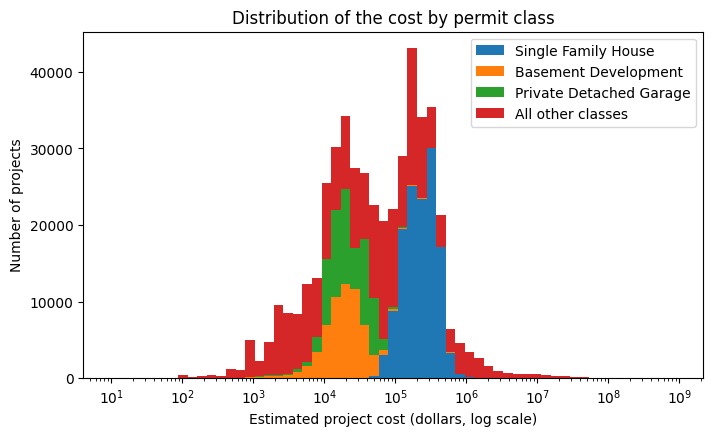

In [15]:
# Name of the three classes that should explain the peaks; all other classes go together
names = {"1106 - Single Family House": "Single Family House",
         "1101 - Basement Development": "Basement Development",
         "1301 - Private Detached Garage": "Private Detached Garage"}
data = df.loc[df["estprojectcost_clean"].notna()]
cls = data["permitclass"].map(names).fillna("All other classes")

# Stacked histogram on the same log bins as in Q2.2
bins = np.logspace(1, np.log10(c.max()), 60)
labels = list(names.values()) + ["All other classes"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([data.loc[cls == l, "estprojectcost_clean"] for l in labels], bins=bins, stacked=True, label=labels)
ax.set_xscale("log")
ax.set_xlabel("Estimated project cost (dollars, log scale)")
ax.set_ylabel("Number of projects")
ax.set_title("Distribution of the cost by permit class")
ax.legend()
plt.show()

The chart confirms most of the idea. The right peak is mainly new Single Family houses (blue) and the left peak is basement developments (orange) and detached garages (green). But these three classes do not explain everything: the other classes (red) make up about half of each peak and also have two humps, and the small spike near 1,000 dollars belongs to them too. The two peaks reflect many kinds of work, not just houses against basements.

### Q2.4.4 Comparison of the groups

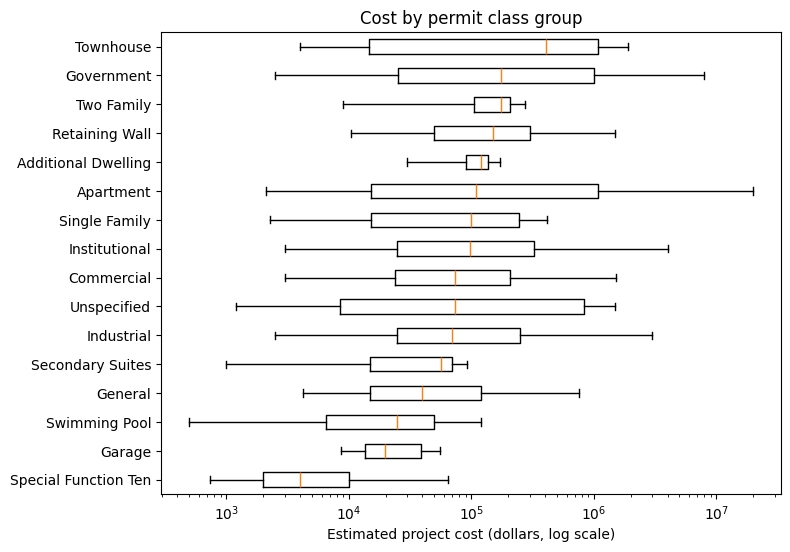

In [16]:
# Cost of each group, from the group with the highest median (top) to the lowest (bottom)
order = list(stats.index)[::-1]
by_group = [df.loc[(df["permitclassgroup"] == g) & df["estprojectcost_clean"].notna(), "estprojectcost_clean"]
            for g in order]

# Boxplots on a log scale: box from p25 to p75, whiskers from p5 to p95
fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(by_group, vert=False, whis=(5, 95), showfliers=False)
ax.set_yticklabels(order)
ax.set_xscale("log")
ax.set_xlabel("Estimated project cost (dollars, log scale)")
ax.set_title("Cost by permit class group")
plt.show()

The median cost goes from 4,000 dollars (Special Function) to 410,351 (Townhouse), a difference of two orders of magnitude. The boxes of Townhouse, Apartment, Government and Unspecified are very wide: half of their projects span about two orders of magnitude, so a single typical cost does not describe them. Garage, Additional Dwelling and Two Family are narrow and regular. The boxes of most groups overlap a lot, so a different median does not mean that the groups are clearly separated.

## Q2.5 Cost over the years

The costs are in current dollars of each year, without adjusting for inflation, so a trend mixes real growth with price changes. Only full years (2000 to 2025) are used, as in Q1.5. The inflation adjustment is an extension in Part B.

                       p25       p50        p75  projects  total (billion)
application_year                                                          
2000              12440.74  76948.00  133371.75     12920             2.02
2001              12440.74  81255.15  135113.62     14362             1.96
2002              12599.69  90622.10  143133.88     16592             2.26
2003              12000.00  89352.60  147002.90     15861             2.44
2004              12029.78  88781.60  154348.40     16053             2.38
2005              12394.75  97571.30  164236.99     18680             3.59
2006              11762.59  81836.40  172250.03     19750             4.73
2007              10691.74  24267.02  203068.52     17562             5.52
2008              13257.49  22000.00  176768.80     14231             3.95
2009              14223.39  26829.11  207379.54     15080             3.65
2010              15424.59  31593.73  231394.30     15222             2.91
2011              15676.3

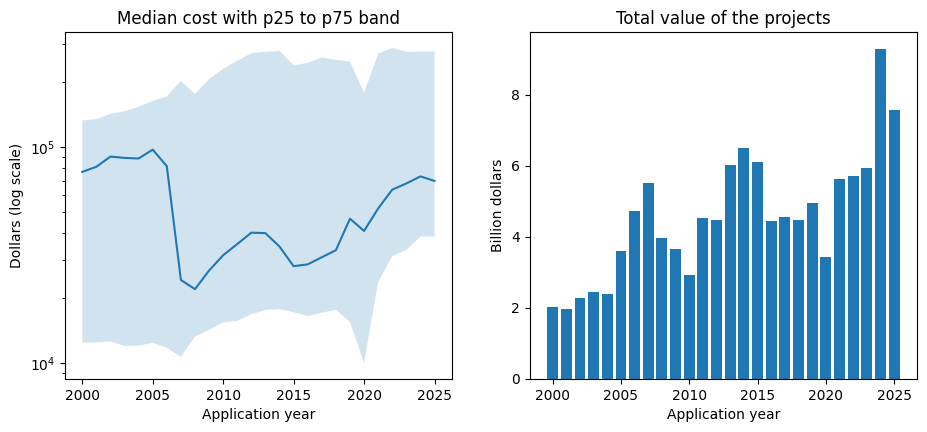

In [17]:
# Projects with a cost in full application years
d = df[df["full_year"] & df["estprojectcost_clean"].notna()]

# Number of projects, percentiles and total value by year
by_year = d.groupby("application_year")["estprojectcost_clean"]
years = by_year.quantile([0.25, 0.5, 0.75]).unstack()
years.columns = ["p25", "p50", "p75"]
years["projects"] = by_year.size()
years["total (billion)"] = by_year.sum() / 1e9
print(years.round(2).to_string())

# Median with its p25 to p75 band (left) and total value (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(years.index, years["p50"])
axes[0].fill_between(years.index, years["p25"], years["p75"], alpha=0.2)
axes[0].set_yscale("log")
axes[0].set_title("Median cost with p25 to p75 band")
axes[0].set_ylabel("Dollars (log scale)")
axes[1].bar(years.index, years["total (billion)"])
axes[1].set_title("Total value of the projects")
axes[1].set_ylabel("Billion dollars")
for ax in axes:
    ax.set_xlabel("Application year")
plt.show()

The median cost is not stable. It is between 77,000 and 98,000 dollars from 2000 to 2006, falls to 24,267 in 2007, stays between 22,000 and 47,000 until 2020 and rises to 73,357 in 2024 and 69,864 in 2025. The total value grows from 2.0 billion dollars in 2000 to a peak of 9.3 billion in 2024, with falls around 2008 to 2010 and in 2020. These are current dollars, so part of the growth is inflation. From 2024 the 25th percentile is exactly 38,576, the fixed garage amount of Q2.2.1. The fall of the median in 2007 needs a closer look, which is done in Q2.5.1.

### Q2.5.1 The fall of the median in 2007

In [18]:
# Share of projects (%) and median cost by permit class group, years around the fall
around = d[d["application_year"].between(2005, 2008)]

share = pd.crosstab(around["permitclassgroup"], around["application_year"], normalize="columns") * 100
median = around.pivot_table(index="permitclassgroup", columns="application_year",
                            values="estprojectcost_clean", aggfunc="median")

# Keep the groups that are at least 3% of the projects in some year, ordered by their share in 2006
big = share.index[(share >= 3).any(axis=1)]
print("Share of projects (%)")
print(share.loc[big].sort_values(2006, ascending=False).round(1).to_string(), "\n")
print("Median cost (dollars)")
print(median.loc[share.loc[big].sort_values(2006, ascending=False).index].map(lambda v: f"{v:,.0f}").to_string())

Share of projects (%)
application_year  2005  2006  2007  2008
permitclassgroup                        
Single Family     66.2  63.1  59.4  56.8
Garage            11.8  15.3  17.8  17.7
Commercial        12.9  11.7  12.0  14.6
Two Family         4.5   4.8   5.0   5.5 

Median cost (dollars)
application_year     2005     2006     2007     2008
permitclassgroup                                    
Single Family     132,708  134,473  131,047   22,608
Garage             11,374   11,761   11,664   15,994
Commercial         53,700   55,000   75,000   85,000
Two Family         85,910   87,203  133,578  127,179


In [19]:
# Share of projects below 50,000 dollars (the valley between the two peaks) next to the median, by year
small_share = (d["estprojectcost_clean"] < 50000).groupby(d["application_year"]).mean() * 100
check = pd.DataFrame({"share below 50,000 (%)": small_share.round(1), "median": years["p50"].round(0)})
print(check.to_string())

                  share below 50,000 (%)   median
application_year                                 
2000                                41.8  76948.0
2001                                40.7  81255.0
2002                                38.3  90622.0
2003                                40.8  89353.0
2004                                42.9  88782.0
2005                                41.2  97571.0
2006                                45.7  81836.0
2007                                53.6  24267.0
2008                                59.4  22000.0
2009                                55.2  26829.0
2010                                53.4  31594.0
2011                                52.2  35603.0
2012                                51.1  40224.0
2013                                51.4  40000.0
2014                                53.8  34670.0
2015                                59.6  28104.0
2016                                59.0  28670.0
2017                                56.4  30924.0


The mix of work changes slowly in these years: Single Family goes from 66% to 57% of the projects and Garage from 12% to 18% between 2005 and 2008. The median, however, falls at once, because the distribution has two peaks. The share of projects below 50,000 dollars, the valley between them, goes from 45.7% in 2006 to 53.6% in 2007. When it passes 50%, the median moves from the right peak to the left one, and it comes back when the share falls below 50% in 2021. The fall of 2007 and the rise after 2021 are therefore threshold effects: a change of about 8 points in the share of small projects moves the median more than three times. The median alone is a poor summary of the cost over time, and the percentiles and the share of small projects describe it better.

## Q2.6 Applications without cost

In [20]:
# Applications without a usable cost, by permit type
miss = df.groupby("permittype")["estprojectcost_clean"].agg(applications="size", missing=lambda s: s.isna().sum())
miss["missing (%)"] = (miss["missing"] / miss["applications"] * 100).round(1)
print(miss.sort_values("missing (%)", ascending=False).to_string())
print("\nTotal missing:", f"{miss['missing'].sum():,}", "of", f"{miss['applications'].sum():,}")

                                   applications  missing  missing (%)
permittype                                                           
Demolition                                17680    17680        100.0
Environmental Restoration Permit            747      146         19.5
Residential Improvement Project          226823    14117          6.2
Commercial / Multi Family Project        101057     5212          5.2
Single Construction Permit               156507     2385          1.5

Total missing: 39,540 of 502,814


Demolition never has a cost: all 17,680 applications are missing, which is 44.7% of the 39,540 missing values. Without Demolition, 21,860 of 485,134 applications (4.5%) have no usable cost. By type, Environmental Restoration is missing the most (19.5%), followed by Residential Improvement (6.2%), Commercial / Multi Family (5.2%) and Single Construction Permit (1.5%). The cost cannot describe demolitions, so every result of this notebook is about the other four types.

In [21]:
# Share of applications without cost by application year, leaving out Demolition (always missing)
nd = df[(df["permittype"] != "Demolition") & df["full_year"]]
miss_year = nd.groupby("application_year")["estprojectcost_clean"].agg(
    applications="size", missing=lambda s: s.isna().sum())
miss_year["missing (%)"] = (miss_year["missing"] / miss_year["applications"] * 100).round(1)
print(miss_year.to_string())

                  applications  missing  missing (%)
application_year                                    
2000                     13221      301          2.3
2001                     14645      283          1.9
2002                     16921      329          1.9
2003                     16157      296          1.8
2004                     16381      328          2.0
2005                     19016      336          1.8
2006                     20073      323          1.6
2007                     18085      523          2.9
2008                     14716      485          3.3
2009                     15360      280          1.8
2010                     15422      200          1.3
2011                     15689      208          1.3
2012                     16772      214          1.3
2013                     18151      306          1.7
2014                     18597      283          1.5
2015                     15849      426          2.7
2016                     14865      444       

Without Demolition, the share of applications without a cost is low from 2000 to 2017 (between 1.3% and 3.3%), rises to 4.8% and 5.0% in 2018 and 2019 and stays between 8.3% and 10.9% from 2020 to 2025. In the recent years about one in ten applications has no usable cost, so the figures of Q2.5 for those years describe a less complete part of the data. The missing values are not spread evenly in time, so it is worth seeing which kinds of work they belong to.

In [22]:
# Periods of application, same bins and labels as in Question 1
nd_all = df[df["permittype"] != "Demolition"].copy()
nd_all["period"] = pd.cut(nd_all["application_year"], bins=[1998, 2016, 2020, 2026],
                          labels=["Before (1999-2016)", "Transition (2017-2020)", "Recent (2021-2026)"])

# Share of applications without cost (%) by permit class group and period (Demolition left out)
nd_all["no_cost"] = nd_all["estprojectcost_clean"].isna() * 100
by_group = nd_all.pivot_table(index="permitclassgroup", columns="period", values="no_cost",
                              aggfunc="mean", observed=True)
by_group["applications"] = nd_all.groupby("permitclassgroup").size()

# Keep the groups with enough applications, ordered by the recent period
by_group = by_group[by_group["applications"] >= MIN_N].sort_values("Recent (2021-2026)", ascending=False)
print(by_group.round(1).to_string())

period                Before (1999-2016)  Transition (2017-2020)  Recent (2021-2026)  applications
permitclassgroup                                                                                  
Unspecified                         99.7                    44.1                64.5         10176
Special Function Ten                 1.6                     4.9                12.7          3521
Institutional                        3.2                     5.5                12.2          9577
Commercial                           2.2                     4.3                10.8         61742
Industrial                           3.3                     2.9                10.3          5470
Swimming Pool                        2.6                    10.4                 8.7           625
General                              4.9                     2.1                 6.4          2461
Additional Dwelling                  3.6                     9.1                 6.4          1152
Secondary 

The group Unspecified is the main source of missing costs: 99.7% of its applications have no cost before 2017, 44.1% in the transition and 64.5% from 2021. It has 10,176 applications and holds 6,502 of the 21,860 missing values outside Demolition (29.7%). The rise of the missing share in recent years also appears in the groups with known work: Commercial (2.2% before 2017 and 10.8% from 2021), Institutional (3.2% to 12.2%), Industrial (3.3% to 10.3%) and Special Function (1.6% to 12.7%). Single Family, the largest group, goes from 1.3% to 5.3%. Why the cost is missing is a question for Question 5, which studies the missing data of the whole table.

## Summary of Part A

- **Coverage.** 463,274 of the 502,814 applications (92.1%) have a usable cost. The 39,540 without it include all 17,680 demolitions and 21,860 other applications (4.5%), mostly in the group Unspecified. The missing share rises from about 2% before 2018 to 8% to 11% from 2020.
- **Distribution.** The median cost is 55,549 dollars and the mean is 273,660 (skewness 116.6). The 99th percentile is 2.35 million and the largest project is 868 million. On the log scale there are two peaks, near 20,000 and 150,000 dollars: basement developments and garages on the left, new houses on the right, and many other classes on both.
- **Round and fixed values.** One in five costs is a multiple of 1,000. Two fixed amounts, 38,576 and 42,433.60, appear in 7,218 applications of one class (Private Detached Garage), so for that class the cost is not an estimate of each project.
- **Concentration.** The 463 largest projects (0.1%) hold 23.1% of the 126.8 billion dollars, the largest 1% hold 47.6% and the cheaper half holds 3.5%.
- **By class.** Median costs go from 4,000 (Special Function) to 410,351 (Townhouse). Townhouse, Apartment, Government and Unspecified are very wide groups, and Single Family mixes new houses and small improvements.
- **Over the years.** The median falls from 81,836 dollars in 2006 to 24,267 in 2007 and recovers from 2021. This is a threshold effect of the two peaks: the share of projects below 50,000 dollars crosses 50% in 2007 and falls below it in 2021. The total value grows from 2.0 billion dollars in 2000 to 9.3 billion in 2024, in current dollars.

The distribution has two peaks and a heavy tail, so the median alone follows the peaks. Part B checks how far a lognormal curve fits, measures the uncertainty of the medians and models the cost quantiles.

# **Part B: Going deeper**

| Section | Topic | What it shows |
|---|---|---|
| Q2.7 | Methods | The checks and models used, and why |
| Q2.8 | Lognormal fit check | How far one lognormal curve describes the cost, overall and by class group |
| Q2.9 | Robust summaries and bootstrap intervals | The stability of the mean, the median and the concentration of value |
| Q2.10 | Regression and quantile regression | How the mean, the median and the upper quantiles change with class group and year |
| Q2.11 | Inflation adjustment | The trend over the years in constant dollars |
| Q2.12 | Sensitivity checks | Key results without the doubtful rows and with other cleaning limits |
| Summary | Summary of Part B | What the formal methods add |
| Conclusion | Conclusion of Question 2 | The answer to the question, key figures and limits |

Part B extends the EDA of Part A. The EDA describes the project cost and finds patterns, and Part B checks whether those patterns are real, how large they are, and how certain the estimates are.

| | Part A: EDA (main point) | Part B: extension |
|---|---|---|
| Purpose | Describe the data and find patterns | Check whether the patterns are real, how large, and how certain |
| Tools | Tables, percentiles, histograms on the log scale, concentration tables, yearly trends | Lognormal fit check, bootstrap intervals, quantile regression, inflation adjustment |
| Example in Question 2 | Townhouse has the highest median cost and Garage one of the lowest | Bootstrap intervals show how certain those medians are, and quantile regression shows if the differences hold after accounting for the year |

Two points about the boundary between the parts. The inflation adjustment also describes the cost over the years, but it needs an external price index and belongs with the formal methods. And the permit class groups were chosen after looking at the data (section Q2.4), so the comparisons by group stay exploratory, even in Part B.

## Q2.7 Methods

The cost is very skewed (section Q2.2), has two peaks and repeated values, and a few very large projects hold much of the total value (section Q2.3). Summaries and tests that assume a bell shape or react to the extremes would mislead here. The methods below either make no assumption about the distribution, or test the assumption, and they show how stable each result is.

| Question | Method | Why this method |
|---|---|---|
| Does one lognormal curve describe the cost? | Lognormal fit check: Q-Q plot of the log cost and observed against fitted percentiles | Costs are often modelled as lognormal. A good fit would allow a simple summary, and a poor fit shows that percentiles are needed |
| How much does the tail move the usual summaries? | Robust summaries: trimmed mean and median absolute deviation, next to the mean and the standard deviation | A few very large projects move the mean, so robust measures show how much of it comes from the tail |
| How certain are the medians and the concentration of value? | Bootstrap intervals for the median by class group and by year, and for the share of value held by the largest 1% | The median and the share have no simple formula for their uncertainty with a skewed cost and repeated values, and the bootstrap needs no assumption |
| How do the mean, the median and the upper quantiles change with class group and year? | Regression of the log cost as a baseline, and quantile regression | The mean model describes the average of the log cost, and quantile regression describes the median and the upper quantiles. The comparison shows what the mean model hides |
| What is the trend over the years once prices are taken into account? | Adjustment with the Consumer Price Index, which gives the cost in constant dollars | The trend in current dollars mixes real growth and price changes |
| Do the results depend on the doubtful rows and on the cleaning choices? | Key results repeated without the fixed garage amounts, without the largest projects and with other lower cleaning limits | These are the data and the choices that can move the results the most. If the conclusions do not change, they are robust |

**Lognormal fit check.** A lognormal distribution is the usual model for costs: the logarithm of the cost follows a normal bell shape. The check compares the log cost with a normal distribution (Q-Q plot) and the observed percentiles with those of the fitted curve. With 463,274 projects a formal test rejects almost any model, so the check is graphical and by percentiles. The histogram of Q2.2 already shows two peaks, so deviations are expected, and the check is repeated inside the largest permit class groups.

**Robust summaries.** The mean and the standard deviation depend on the extreme values. The trimmed mean drops a fixed share of the smallest and the largest projects, and the median absolute deviation measures the spread around the median in a way that the extremes hardly change. Comparing them with the mean and the standard deviation shows how much of the usual summary comes from the tail.

**Bootstrap intervals.** The bootstrap draws many samples of the same size from the projects, with replacement, computes the statistic in each sample and uses the 2.5th and 97.5th percentiles as a 95% interval. It is applied to the median by class group and by year, and to the share of the total value held by the largest 1% of projects, which depends on a few very large projects. The intervals are expected to be narrow for large groups and wide for small ones.

**Regression and quantile regression.** An ordinary regression of the log cost models the mean of the log cost, which is a typical project only when the distribution has one peak and no heavy tail. It is fitted as a baseline, with the permit class group and the application year as predictors. Quantile regression uses the same model for a chosen quantile, so the median and the upper quantiles are described separately, and the coefficients are ratios because the model uses the log of the cost. Fitting several quantiles shows if the differences between groups are the same for typical projects and for the largest ones.

**Inflation adjustment.** The costs are in current dollars of each year, so the trend of section Q2.5 mixes real growth and price changes. Dividing each cost by the Consumer Price Index of its year puts all projects in constant dollars. The result is compared with the trend in current dollars.

**Sensitivity checks.** The two fixed garage amounts (7,218 applications, section Q2.2.1) and the largest projects (section Q2.3) are the data that can move the results the most. The lower limit used in Phase 1 to clean the cost (10 dollars) is also a choice, so it is repeated at 100 and 1,000 dollars. The key results are computed again in each case to see if the conclusions change.

**Where it continues in the series.** Quantile regression and the regression baseline are developed further in Project 5 (Regression analysis). The bootstrap, the robust summaries and the sensitivity checks are developed further in Project 10 (Robustness, sensitivity and uncertainty). In this notebook they are a first, lighter use on one question.

## Q2.8 Lognormal fit check

The lognormal curve is fitted with the mean and the standard deviation of the log cost. In the Q-Q plot, each point compares a quantile of the log cost with the same quantile of the fitted normal distribution. Points on the diagonal mean a good fit, and the distance from the diagonal shows where the fit fails.

Mean of the log cost: 10.87 | standard deviation: 1.74 | fitted median: 52,464 dollars



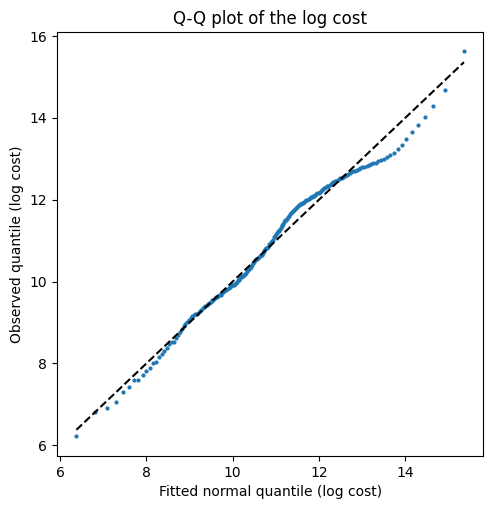

         observed      fitted
0.010         900         908
0.050       2,500       2,981
0.250      15,778      16,185
0.500      55,549      52,464
0.750     200,000     170,057
0.900     370,476     490,085
0.950     515,146     923,356
0.990   2,351,670   3,029,757
0.999  25,366,829  11,477,138


In [23]:
# Mean and standard deviation of the log cost define the fitted lognormal curve
from scipy import stats as sps
log_c = np.log(c)
mu, sigma = log_c.mean(), log_c.std()
print(f"Mean of the log cost: {mu:.2f} | standard deviation: {sigma:.2f} | fitted median: {np.exp(mu):,.0f} dollars\n")

# Q-Q plot: observed quantiles of the log cost against the fitted normal quantiles
probs = np.linspace(0.005, 0.995, 199)
observed = log_c.quantile(probs)
fitted = sps.norm.ppf(probs, mu, sigma)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fitted, observed, ".", markersize=4)
ax.plot([fitted.min(), fitted.max()], [fitted.min(), fitted.max()], color="black", linestyle="--")
ax.set_xlabel("Fitted normal quantile (log cost)")
ax.set_ylabel("Observed quantile (log cost)")
ax.set_title("Q-Q plot of the log cost")
plt.show()

# Observed and fitted percentiles in dollars
p = [0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
table = pd.DataFrame({"observed": c.quantile(p).values, "fitted": np.exp(sps.norm.ppf(p, mu, sigma))}, index=p)
print(table.map(lambda v: f"{v:,.0f}").to_string())

The lognormal curve fits the middle of the distribution well. The percentiles from the 1st to the 75th are within about 20% of the observed ones (for example 15,778 observed against 16,185 fitted at the 25th, and 55,549 against 52,464 at the median), and the points of the Q-Q plot stay close to the diagonal between about 8,000 and 270,000 dollars. The fit fails in the upper tail in two ways. Between the 90th and the 99th percentile the fitted curve is too high (515,146 observed against 923,356 fitted at the 95th), and at the 99.9th it is too low (25.4 million observed against 11.5 million fitted). The wave of the points around the diagonal is the trace of the two peaks. A lognormal curve is therefore a reasonable summary of the typical project, but it understates the largest projects.

### Q2.8.1 Fit inside the largest groups

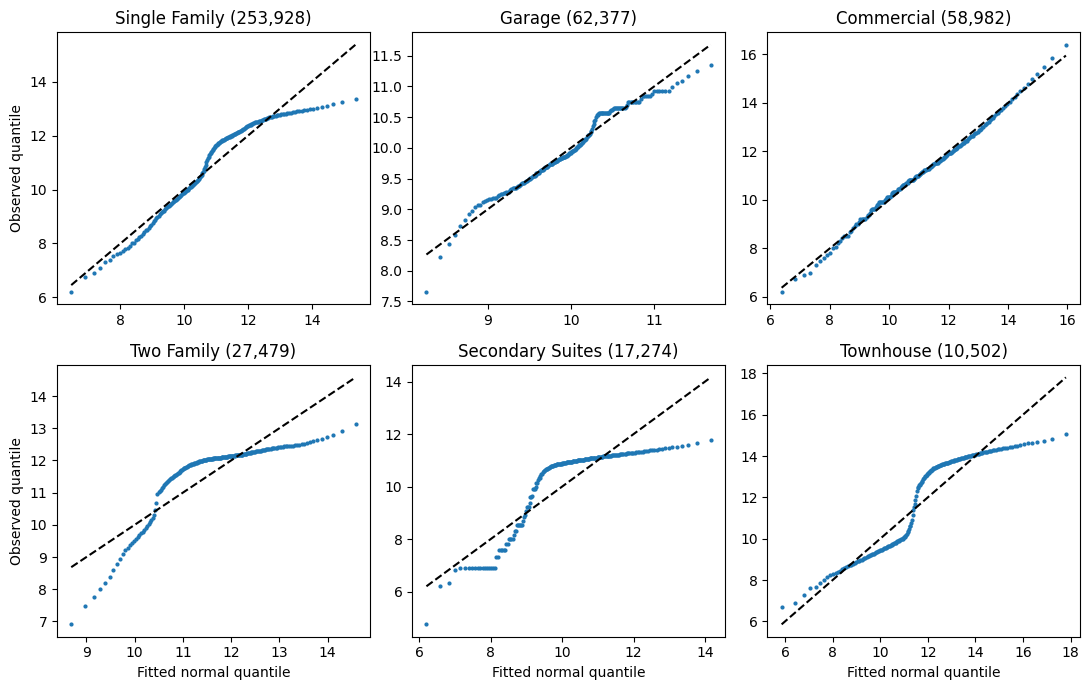

In [24]:
# Q-Q plot of the log cost inside the six permit class groups with most projects
top6 = df.loc[df["estprojectcost_clean"].notna(), "permitclassgroup"].value_counts().head(6).index
probs = np.linspace(0.005, 0.995, 199)

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, name in zip(axes.ravel(), top6):
    lc = np.log(df.loc[(df["permitclassgroup"] == name) & df["estprojectcost_clean"].notna(), "estprojectcost_clean"])
    # Each group is compared with a normal curve fitted to its own log cost
    fit = sps.norm.ppf(probs, lc.mean(), lc.std())
    ax.plot(fit, lc.quantile(probs), ".", markersize=4)
    ax.plot([fit.min(), fit.max()], [fit.min(), fit.max()], color="black", linestyle="--")
    ax.set_title(f"{name} ({len(lc):,})")
for ax in axes[1]:
    ax.set_xlabel("Fitted normal quantile")
for ax in axes[:, 0]:
    ax.set_ylabel("Observed quantile")
plt.tight_layout()
plt.show()

The fit depends strongly on the group. Commercial follows the diagonal almost perfectly, including the tails, so a lognormal curve describes it well. Garage also fits in the middle, with a step near 38,576 dollars (the fixed amount of Q2.2.1). In the other four groups the points form an S: Single Family has a much lighter upper tail than the lognormal curve, Two Family concentrates between about 60,000 and 270,000 dollars, Secondary Suites has a flat part at about 1,000 dollars and another at about 60,000 (repeated values), and Townhouse has two clusters, one below 25,000 and one above 150,000. The lognormal curve is a good model only where the group is homogeneous. Where a group mixes kinds of work or has repeated amounts, its percentiles are better described directly.

## Q2.9 Robust summaries and bootstrap intervals



### Q2.9.1 Robust summaries

The trimmed mean drops the lowest 10% and the highest 10% of the projects before averaging. The median absolute deviation (MAD) is scaled so that it matches the standard deviation when the data are normal, which allows comparing the two.

In [25]:
# Mean, trimmed mean, median, standard deviation and MAD for all projects and the six largest groups
def summaries(x):
    return {"projects": len(x), "mean": x.mean(), "trimmed mean (10%)": sps.trim_mean(x, 0.1),
            "median": x.median(), "std": x.std(), "MAD (scaled)": sps.median_abs_deviation(x, scale="normal")}

has_cost = df[df["estprojectcost_clean"].notna()]
rows = {"All projects": summaries(has_cost["estprojectcost_clean"])}
for name in top6:
    rows[name] = summaries(has_cost.loc[has_cost["permitclassgroup"] == name, "estprojectcost_clean"])

result = pd.DataFrame(rows).T
print(result.map(lambda v: f"{v:,.0f}").to_string())

                 projects     mean trimmed mean (10%)   median        std MAD (scaled)
All projects      463,274  273,660            103,151   55,549  3,266,365       74,945
Single Family     253,928  143,022            122,379  100,000    150,657      133,434
Garage             62,377   26,292             24,286   19,921     18,709       12,650
Commercial         58,982  540,140            126,509   73,500  6,017,493       91,180
Two Family         27,479  160,087            159,372  173,245     97,248       68,127
Secondary Suites   17,274   49,186             48,274   56,764     52,213       26,006
Townhouse          10,502  671,491            519,169  410,351  2,304,786      596,126


The extreme projects move the usual summaries a lot in some groups and hardly at all in others. For all projects the mean (273,660 dollars) is 4.9 times the median and the standard deviation (3.27 million) is 44 times the scaled MAD (74,945). The trimmed mean (103,151) is closer to the median, but still above it because the distribution is skewed. Commercial shows the same pattern in a stronger form (mean 540,140, trimmed mean 126,509, median 73,500), and Townhouse also has a large gap between the standard deviation and the MAD. In Single Family, Garage, Two Family and Secondary Suites the mean and the trimmed mean are close, so the tail matters little there. The heavy tail of the whole table comes mostly from the non-residential groups.

### Q2.9.2 Bootstrap intervals for the median

Each group is resampled 1,000 times with replacement, keeping its size, and the median is computed in every sample. The 2.5th and 97.5th percentiles of those medians form a 95% interval. A fixed seed makes the result repeatable.

In [26]:
# Bootstrap 95% interval for the median cost of each permit class group
rng = np.random.default_rng(42)      # fixed seed, so the intervals repeat
B = 1000                             # number of resamples

rows = []
for name, g in has_cost.groupby("permitclassgroup")["estprojectcost_clean"]:
    x = g.to_numpy()
    # Median of each resample of the same size, drawn with replacement
    medians = np.array([np.median(rng.choice(x, size=len(x))) for _ in range(B)])
    low, high = np.percentile(medians, [2.5, 97.5])
    rows.append({"group": name, "projects": len(x), "median": np.median(x), "low": low, "high": high,
                 "width (% of median)": (high - low) / np.median(x) * 100})

boot = pd.DataFrame(rows).set_index("group").sort_values("median", ascending=False)
print(boot.round(1).map(lambda v: f"{v:,.1f}" if abs(v) < 1000 else f"{v:,.0f}").to_string())

                     projects   median      low     high width (% of median)
group                                                                       
Townhouse              10,502  410,351  363,935  447,500                20.4
Government              915.0  173,400  126,000  200,000                42.7
Two Family             27,479  173,245  172,817  173,898                 0.6
Retaining Wall           94.0  150,000  115,500  209,000                62.3
Additional Dwelling     1,079  119,554  115,391  122,385                 5.8
Apartment               6,562  110,000  100,000  121,683                19.7
Single Family         253,928  100,000   98,763  100,478                 1.7
Institutional           8,947   98,000   90,000  100,000                10.2
Commercial             58,982   73,500   70,000   75,000                 6.8
Unspecified             3,674   73,490   67,223   80,500                18.1
Industrial              5,197   70,000   65,000   75,000                14.3

The intervals are narrow for the large groups with repeated values: Two Family (0.6% of the median), Secondary Suites (1.5%), Single Family (1.7%) and Garage (2.4%). They are wide for the small groups: Retaining Wall (94 projects, 62.3%), Government (915 projects, 42.7%) and Swimming Pool (590 projects, 40.0%). The size of the group is not the only factor. Townhouse has 10,502 projects and an interval of 20.4%, much wider than Commercial (58,982 projects, 6.8%), because its median falls between two clusters of costs (Q2.8.1), so a few projects moving from one cluster to the other change it. Several medians cannot be told apart: Single Family and Institutional overlap (98,763 to 100,478 against 90,000 to 100,000), and so do Commercial, Unspecified and Industrial. Because of the repeated amounts, the medians of the resamples take few distinct values, and some limits coincide with the median (for example 56,764 in Secondary Suites).

### Q2.9.3 Bootstrap interval for the concentration of value

In [27]:
# Share of the total value held by the largest 0.1% and 1% of the projects, with bootstrap intervals
x = c.to_numpy()
n = len(x)

def top_share(values, fraction):
    k = int(len(values) * fraction)
    return np.partition(values, len(values) - k)[len(values) - k:].sum() / values.sum() * 100

rows = []
for fraction in [0.001, 0.01]:
    # Share in each resample of the same size, drawn with replacement (B and rng from Q2.9.2)
    shares = [top_share(rng.choice(x, size=n), fraction) for _ in range(B)]
    low, high = np.percentile(shares, [2.5, 97.5])
    rows.append({"largest projects": f"top {fraction * 100:g}%", "observed share (%)": top_share(x, fraction),
                 "low (%)": low, "high (%)": high})

print(pd.DataFrame(rows).round(1).to_string(index=False))

largest projects  observed share (%)  low (%)  high (%)
        top 0.1%                23.1     21.0      25.3
          top 1%                47.6     45.9      49.3


The concentration of value is stable under resampling. The largest 0.1% of the projects hold 23.1% of the total value (95% interval from 21.0% to 25.3%), and the largest 1% hold 47.6% (from 45.9% to 49.3%). The intervals are about two points wide on each side because a few very large projects decide the total: the single largest project holds 0.7% of it. The interval measures the effect of which projects are in the sample. It does not measure errors in the declared costs.

### Q2.9.4 Bootstrap intervals for the median by year

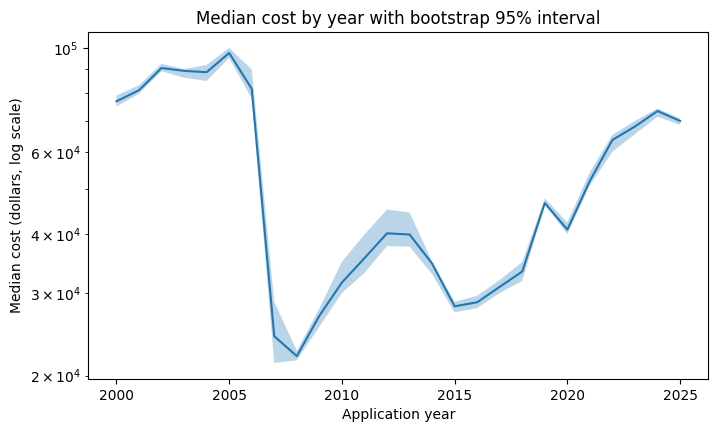

      median     low     high
year                         
2000  76,948  75,000   79,144
2001  81,255  79,894   83,244
2002  90,622  89,203   92,499
2003  89,353  86,393   90,150
2004  88,782  85,050   92,014
2005  97,571  95,227  100,000
2006  81,836  78,000   90,000
2007  24,267  21,276   28,724
2008  22,000  21,554   22,585
2009  26,829  25,431   27,786
2010  31,594  30,000   35,000
2011  35,603  33,119   40,000
2012  40,224  37,780   45,214
2013  40,000  37,667   44,569
2014  34,670  32,920   35,054
2015  28,104  27,273   28,731
2016  28,670  27,866   29,596
2017  30,924  30,000   32,000
2018  33,353  31,852   34,937
2019  46,677  46,291   47,752
2020  40,958  40,090   42,434
2021  52,078  50,920   54,320
2022  63,650  60,051   65,241
2023  68,000  65,498   69,864
2024  73,357  71,348   74,260
2025  69,864  68,527   70,737


In [28]:
# Bootstrap 95% interval for the median cost of each full application year (rng and B from Q2.9.2)
rows = []
for year, g in d.groupby("application_year")["estprojectcost_clean"]:
    x = g.to_numpy()
    medians = np.array([np.median(rng.choice(x, size=len(x))) for _ in range(B)])
    low, high = np.percentile(medians, [2.5, 97.5])
    rows.append({"year": int(year), "median": np.median(x), "low": low, "high": high})
by_year_boot = pd.DataFrame(rows).set_index("year")

# Median with its interval, log scale
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_year_boot.index, by_year_boot["median"])
ax.fill_between(by_year_boot.index, by_year_boot["low"], by_year_boot["high"], alpha=0.3)
ax.set_yscale("log")
ax.set_xlabel("Application year")
ax.set_ylabel("Median cost (dollars, log scale)")
ax.set_title("Median cost by year with bootstrap 95% interval")
plt.show()

print(by_year_boot.round(0).map(lambda v: f"{v:,.0f}").to_string())

The changes of Q2.5 are much larger than the uncertainty of the median. The intervals are narrow in most years (within about 5% of the median), and the fall from 2006 (81,836 dollars, interval 78,000 to 90,000) to 2007 (24,267, interval 21,276 to 28,724) has no overlap, so it is not a matter of chance. The same is true of the rise to 46,677 in 2019 (against 33,353 in 2018) and of the dip in 2020 (40,958). The intervals are wider in 2006 and 2007 and between 2010 and 2013 (up to about 30% of the median in 2007), the years when the share of projects below 50,000 dollars is close to 50%. When the median sits in the valley between the two peaks, a few projects change it, which agrees with the explanation of Q2.5.1.

## Q2.10 Regression and quantile regression

The model explains the log of the cost with the permit class group and the application year. The year enters as one level for each year because the median does not follow a line over time (sections Q2.5 and Q2.9.4), and this also avoids choosing periods after looking at the data. The year is a control: the results of interest are the group effects. Single Family is the reference group because it is the largest. The coefficients are shown as ratios of the cost, where 1.0 means the same cost as Single Family in the same year.



### Q2.10.1 Ordinary regression as a baseline

In [29]:
# Data for the model: log of the cost, permit class group and application year
import statsmodels.formula.api as smf
model_data = has_cost[["estprojectcost_clean", "permitclassgroup", "application_year"]].dropna().copy()
model_data["log_cost"] = np.log(model_data["estprojectcost_clean"])
model_data["year"] = model_data["application_year"].astype(int)

# Ordinary regression of the log cost: baseline for the quantile regression
formula = 'log_cost ~ C(permitclassgroup, Treatment(reference="Single Family")) + C(year)'
ols = smf.ols(formula, data=model_data).fit()

# Group effects as ratios of the cost (1.0 = same as Single Family), with 95% intervals
is_group = ols.params.index.str.startswith("C(permitclassgroup")
ratios = np.exp(pd.concat([ols.params[is_group], ols.conf_int()[is_group]], axis=1))
ratios.columns = ["ratio", "low", "high"]
ratios.index = ratios.index.str.extract(r"\[T\.(.*)\]", expand=False)
print(f"Projects: {int(ols.nobs):,} | R-squared: {ols.rsquared:.2f}")
print(ratios.sort_values("ratio", ascending=False).round(2).to_string())

Projects: 463,274 | R-squared: 0.11
                      ratio   low  high
Government             2.69  2.42  2.99
Apartment              2.50  2.40  2.60
Retaining Wall         2.37  1.70  3.31
Townhouse              2.34  2.26  2.41
Two Family             1.92  1.88  1.96
Institutional          1.65  1.59  1.71
Industrial             1.42  1.36  1.49
Additional Dwelling    1.37  1.24  1.51
Commercial             1.29  1.27  1.31
Unspecified            1.01  0.96  1.07
General                0.76  0.71  0.81
Garage                 0.38  0.37  0.38
Secondary Suites       0.36  0.35  0.37
Swimming Pool          0.26  0.23  0.29
Special Function Ten   0.08  0.08  0.09


The model shows large differences between groups in the typical log cost. Compared with Single Family in the same year, Government (2.69), Apartment (2.50), Townhouse (2.34) and Two Family (1.92) are higher, and Garage (0.38), Secondary Suites (0.36), Swimming Pool (0.26) and Special Function (0.08) are lower. The intervals are narrow, except for Retaining Wall (94 projects). The group and the year explain only 11% of the variation of the log cost (R-squared of 0.11), so most of the differences are inside the groups, which agrees with the wide groups of Q2.4. These ratios compare the average of the log cost, which depends on the whole distribution and not only on its center. For example, Commercial is 1.29 times Single Family although its median is lower (73,500 dollars against 100,000, section Q2.4.1). The quantile regression below separates the center from the tails.

### Q2.10.2 Quantile regression

The same model is fitted for the quantiles 0.25, 0.5, 0.75 and 0.9 of the log cost. The coefficients are ratios of the cost at that quantile, with Single Family in the same year as reference. The first column repeats the ordinary regression for comparison.

In [30]:
# Quantile regression with the same formula at four quantiles (this can take several minutes)
results = {"mean (OLS)": ratios["ratio"]}
for q in [0.25, 0.5, 0.75, 0.9]:
    fit = smf.quantreg(formula, data=model_data).fit(q=q, max_iter=2000)
    g = fit.params[fit.params.index.str.startswith("C(permitclassgroup")]
    g.index = g.index.str.extract(r"\[T\.(.*)\]", expand=False)
    results[f"q{int(q * 100)}"] = np.exp(g)

quantile_table = pd.DataFrame(results).sort_values("q50", ascending=False)
print(quantile_table.round(2).to_string())

                      mean (OLS)   q25   q50   q75    q90
Townhouse                   2.34  0.88  3.11  3.51   4.08
Retaining Wall              2.37  3.10  1.28  1.04   2.58
Government                  2.69  1.51  1.25  3.50  12.01
Two Family                  1.92  5.58  1.12  0.71   0.69
Apartment                   2.50  0.91  0.86  3.86  30.30
Institutional               1.65  1.55  0.73  1.15   3.60
Commercial                  1.29  1.51  0.61  0.83   2.25
Additional Dwelling         1.37  3.23  0.61  0.38   0.34
Industrial                  1.42  1.44  0.60  1.00   4.21
Unspecified                 1.01  0.35  0.36  2.21   2.73
General                     0.76  0.85  0.32  0.40   0.94
Secondary Suites            0.36  0.93  0.27  0.18   0.18
Swimming Pool               0.26  0.45  0.19  0.19   0.23
Garage                      0.38  1.03  0.18  0.11   0.11
Special Function Ten        0.08  0.11  0.03  0.03   0.07


The ranking of the groups changes with the quantile, which the ordinary regression hides. Commercial is 1.29 times Single Family in the mean model, but at the median it is 0.61 times and only at the 90th quantile it is above (2.25). Apartment is close to Single Family at the median (0.86), but its upper quantiles are far higher: 3.86 at the 75th and 30.30 at the 90th. Government (12.01) and Industrial (4.21) follow the same pattern, so the largest non-residential projects are much larger than the largest houses, while their typical projects are not. Two Family goes the other way: it is 5.58 times Single Family at the 25th quantile and 0.69 at the 90th, because its costs are concentrated in a narrow range while Single Family spreads from basement improvements to new houses. Garage, Secondary Suites and Swimming Pool are well below Single Family at the median and above all at the top (Garage 0.18 at the median and 0.11 at the 90th). Retaining Wall has only 94 projects and its ratios are not stable. The group effects depend on the part of the distribution, so a single ratio per group would not describe them.

### Q2.10.3 Year effects adjusted for the permit class group

The fall of the median in 2007 (section Q2.5.1) can have two explanations: the cost of projects of the same kind really falls, or the mix of kinds of work changes. The model of Q2.10 helps to separate them. It estimates the median of the log cost with one effect for each permit class group and one for each year, so the year effects are already adjusted for the group. The median is refitted with 2000 as the reference year, and each effect is shown as a ratio to the year 2000. The result is compared with the median of each year without adjustment (section Q2.9.4). If the fall of 2007 remains after the adjustment, it comes from the cost within the groups. If it shrinks, it comes mainly from the mix of work.

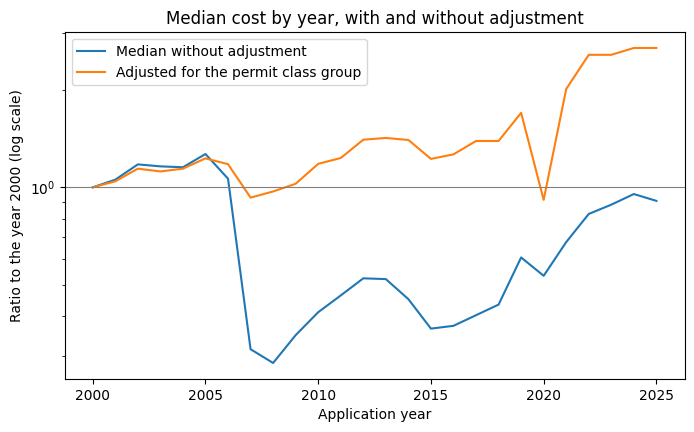

      unadjusted  adjusted
year                      
2000        1.00      1.00
2001        1.06      1.04
2002        1.18      1.14
2003        1.16      1.12
2004        1.15      1.14
2005        1.27      1.23
2006        1.06      1.18
2007        0.32      0.93
2008        0.29      0.97
2009        0.35      1.03
2010        0.41      1.18
2011        0.46      1.23
2012        0.52      1.40
2013        0.52      1.42
2014        0.45      1.40
2015        0.37      1.22
2016        0.37      1.26
2017        0.40      1.39
2018        0.43      1.39
2019        0.61      1.70
2020        0.53      0.91
2021        0.68      2.02
2022        0.83      2.57
2023        0.88      2.57
2024        0.95      2.70
2025        0.91      2.70


In [31]:
# Median regression with 2000 as the reference year, same group effects as before
formula_year = 'log_cost ~ C(permitclassgroup, Treatment(reference="Single Family")) + C(year, Treatment(reference=2000))'
fit50 = smf.quantreg(formula_year, data=model_data).fit(q=0.5, max_iter=2000)

# Year effects adjusted for the group, as ratios to the year 2000
is_year = fit50.params.index.str.startswith("C(year")
adjusted = np.exp(fit50.params[is_year])
adjusted.index = adjusted.index.str.extract(r"\[T\.(\d+)\]", expand=False).astype(int)
adjusted.loc[2000] = 1.0
adjusted = adjusted.sort_index()

# Median of each full year without adjustment, as ratios to the year 2000 (from Q2.9.4)
raw = by_year_boot["median"] / by_year_boot.loc[2000, "median"]
adjusted = adjusted.loc[raw.index]

# Both curves on the log scale
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(raw.index, raw.values, label="Median without adjustment")
ax.plot(adjusted.index, adjusted.values, label="Adjusted for the permit class group")
ax.axhline(1, color="grey", linewidth=0.8)
ax.set_yscale("log")
ax.set_xlabel("Application year")
ax.set_ylabel("Ratio to the year 2000 (log scale)")
ax.set_title("Median cost by year, with and without adjustment")
ax.legend()
plt.show()

print(pd.DataFrame({"unadjusted": raw, "adjusted": adjusted}).round(2).to_string())

Adjusting for the permit class group changes the picture of the yearly median. The unadjusted median falls to 0.32 times its 2000 value in 2007 and is back at 0.91 in 2025, while the adjusted effect has only a small fall in 2007 (0.93, from 1.18 in 2006) and rises to 2.70 in 2024 and 2025. For projects of the same group, the median cost is 2.7 times the cost of 2000 in current dollars, which includes inflation (section Q2.11). The fall of 2007 is much smaller once the group is considered (21% against 70%), so most of it comes from the mix of work and from the two peaks, not from a fall in the cost of projects of the same group. The adjusted dip of 2020 (1.70 in 2019, 0.91 in 2020 and 2.02 in 2021) is larger than in the unadjusted median and needs caution, because quantile coefficients can jump when the median falls on a repeated amount. The model also assumes the same year effect for every group, so it cannot reproduce changes inside one group, such as the fall of the Single Family median between 2007 and 2008 (section Q2.5.1).

## Q2.11 Inflation adjustment

The costs are in current dollars of each year, so a project of 2000 and one of 2025 are not comparable. The adjustment divides each cost by the Consumer Price Index of its application year and multiplies it by the index of 2025, which puts every project in 2025 dollars. The index is the all-items Consumer Price Index of Calgary, annual average, from Statistics Canada (table 18-10-0005-01). The index measures the prices of consumer goods in general, not the cost of construction, so the adjustment is an approximation of the change in the general price level.



### Q2.11.1 The price index

In [32]:
# Download the annual average Consumer Price Index table of Statistics Canada (zipped CSV)
import zipfile
url = "https://www150.statcan.gc.ca/n1/tbl/csv/18100005-eng.zip"
r = requests.get(url, timeout=300)
r.raise_for_status()

# Read the data file of the zip (the other file is the metadata)
with zipfile.ZipFile(io.BytesIO(r.content)) as z:
    name = [n for n in z.namelist() if n.endswith(".csv") and "MetaData" not in n][0]
    cpi_raw = pd.read_csv(z.open(name))

# Check the size, the columns, and whether Calgary and the all-items product are in the file
print(cpi_raw.shape)
print(cpi_raw.columns.tolist())
print([g for g in cpi_raw["GEO"].unique() if "Calgary" in g or "Alberta" in g])
print([p for p in cpi_raw["Products and product groups"].unique() if "All-items" in p])
print("Years:", cpi_raw["REF_DATE"].min(), "to", cpi_raw["REF_DATE"].max())

(94195, 15)
['REF_DATE', 'GEO', 'DGUID', 'Products and product groups', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']
['Edmonton, Alberta', 'Calgary, Alberta', 'Alberta']
['All-items', 'All-items (1992=100)', 'All-items excluding eight of the most volatile components as defined by the Bank of Canada', 'All-items excluding food', 'All-items excluding food and energy', 'All-items excluding energy', "All-items excluding alcoholic beverages, tobacco products and smokers' supplies and recreational cannabis", 'All-items excluding eight of the most volatile components as defined by the Bank of Canada and excluding the effect of changes in indirect taxes', 'All-items excluding mortgage interest cost', 'All-items excluding alcoholic beverages and recreational cannabis', "All-items excluding tobacco products and smokers' supplies and recreational cannabis", 'All-items excluding shelter', 'All-items excluding gasoline

The file has 94,195 rows. It includes Calgary and the all-items index, with annual values up to 2025, so the adjustment can use the Calgary series and no fallback to Alberta is needed.

### Q2.11.2 Factor to 2025 dollars

The factor of each year is the index of 2025 divided by the index of that year, so a cost multiplied by its factor is expressed in 2025 dollars. The series used is "All-items" for Calgary.

In [33]:
# Calgary, all-items Consumer Price Index by year
cpi = cpi_raw[(cpi_raw["GEO"] == "Calgary, Alberta") & (cpi_raw["Products and product groups"] == "All-items")]
cpi = cpi.set_index("REF_DATE")["VALUE"]
cpi.index = cpi.index.astype(int)

# The index must exist for every application year used in the analysis (1999 to 2026)
print("Years of the project without index:", [y for y in range(1999, 2027) if y not in cpi.index])

# Factor to 2025 dollars for each year
cpi_factor = cpi.loc[2025] / cpi
print(pd.DataFrame({"CPI": cpi.loc[2000:2025], "factor to 2025": cpi_factor.loc[2000:2025].round(2)}).to_string())

Years of the project without index: [2026]
            CPI  factor to 2025
REF_DATE                       
2000       94.1            1.86
2001       96.4            1.82
2002      100.0            1.75
2003      103.5            1.69
2004      105.3            1.66
2005      107.4            1.63
2006      112.3            1.56
2007      118.0            1.49
2008      121.8            1.44
2009      121.7            1.44
2010      122.7            1.43
2011      125.4            1.40
2012      126.7            1.38
2013      128.8            1.36
2014      132.7            1.32
2015      134.3            1.31
2016      135.6            1.29
2017      137.8            1.27
2018      141.1            1.24
2019      143.1            1.23
2020      144.7            1.21
2021      149.3            1.17
2022      160.1            1.09
2023      166.2            1.05
2024      171.8            1.02
2025      175.3            1.00


The price level of Calgary rises 1.86 times between 2000 and 2025 (index from 94.1 to 175.3), so a cost of 2000 is multiplied by 1.86 to express it in 2025 dollars. The index exists for all the application years of the analysis except 2026, which is incomplete and stays out of the adjusted results, as in Q2.5. The prices grow slowly until 2020 and faster from 2021 (the factor falls from 1.21 to 1.00 in five years).

### Q2.11.3 Median and total value in 2025 dollars

Each cost is multiplied by the factor of its application year. The yearly median and the total value (full years 2000 to 2025, as in Q2.5) are shown in current dollars and in 2025 dollars. The difference between the two lines is the effect of the price level.

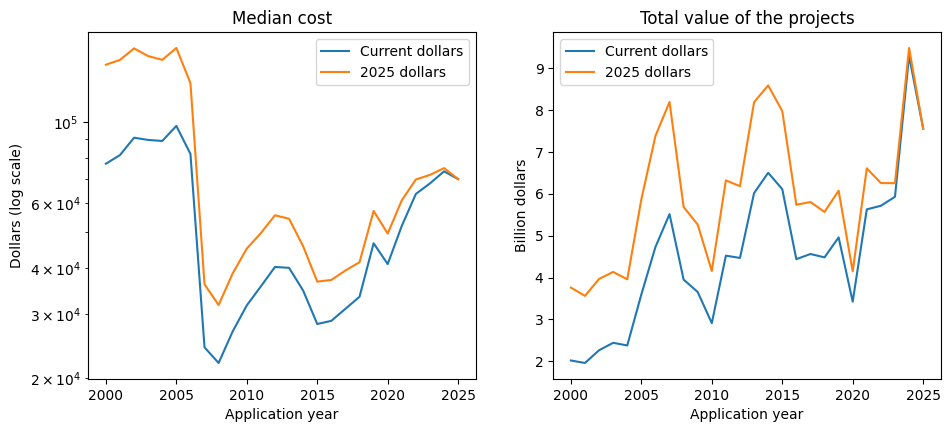

                 median current median 2025 total current (billion) total 2025 (billion)
application_year                                                                        
2000                     76,948     143,347                     2.0                  3.8
2001                     81,255     147,760                     2.0                  3.6
2002                     90,622     158,860                     2.3                  4.0
2003                     89,353     151,338                     2.4                  4.1
2004                     88,782     147,801                     2.4                  4.0
2005                     97,571     159,257                     3.6                  5.9
2006                     81,836     127,746                     4.7                  7.4
2007                     24,267      36,051                     5.5                  8.2
2008                     22,000      31,663                     4.0                  5.7
2009                 

In [34]:
# Cost in 2025 dollars: each cost times the factor of its application year (full years only, from Q2.5)
d = d.copy()
d["cost_2025"] = d["estprojectcost_clean"] * d["application_year"].astype(int).map(cpi_factor)

# Median and total value by year, in current dollars and in 2025 dollars
by_year_real = pd.DataFrame({
    "median current": d.groupby("application_year")["estprojectcost_clean"].median(),
    "median 2025": d.groupby("application_year")["cost_2025"].median(),
    "total current (billion)": d.groupby("application_year")["estprojectcost_clean"].sum() / 1e9,
    "total 2025 (billion)": d.groupby("application_year")["cost_2025"].sum() / 1e9})

# Median (left, log scale) and total value (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(by_year_real.index, by_year_real["median current"], label="Current dollars")
axes[0].plot(by_year_real.index, by_year_real["median 2025"], label="2025 dollars")
axes[0].set_yscale("log")
axes[0].set_title("Median cost")
axes[0].set_ylabel("Dollars (log scale)")
axes[0].legend()
axes[1].plot(by_year_real.index, by_year_real["total current (billion)"], label="Current dollars")
axes[1].plot(by_year_real.index, by_year_real["total 2025 (billion)"], label="2025 dollars")
axes[1].set_title("Total value of the projects")
axes[1].set_ylabel("Billion dollars")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Application year")
plt.show()

print(by_year_real.round(1).map(lambda v: f"{v:,.1f}" if v < 1000 else f"{v:,.0f}").to_string())

In 2025 dollars the median cost of all projects together does not recover. It is 143,347 dollars in 2000, falls to 36,051 in 2007 and is 69,864 in 2025, half of its level in 2000, so the pooled median ends below the starting point even after prices are taken into account. For projects of the same permit class group the median rises: the adjusted effect of Q2.10.3 is 2.70 times the year 2000 in current dollars, which is about 1.45 times in 2025 dollars (2.70 divided by the price factor of 1.86). The two results can both hold only if the mix of work changed towards cheaper projects, which agrees with the explanation of Q2.5.1. The total value in 2025 dollars goes from 3.8 billion dollars in 2000 to 9.5 billion in 2024 and 7.6 billion in 2025, with dips in 2010 (4.2) and 2020 (4.1) and peaks in 2007 (8.2), 2014 (8.6) and 2024. Part of this growth is volume: the number of projects with a cost goes from 12,920 in 2000 to 23,384 in 2024.

## Q2.12 Sensitivity checks

Four choices can move the results the most: the two fixed garage amounts (7,218 applications, section Q2.2.1), the largest projects (section Q2.3) and the lower limit of 10 dollars used in Phase 1 to clean the cost. The key results are computed again in each case: without the fixed amounts, without the largest 0.1% of the projects, and with the lower limit raised to 100 and to 1,000 dollars. The measures are the number of projects, the median, the mean, the trimmed mean, the share of the total value held by the largest 1%, and the median of 2006 and 2007, which shows if the fall of section Q2.5.1 depends on any of these choices. If the conclusions do not change, they are robust to these choices.

In [35]:
# Rows kept in each variant (the fixed amounts are the two values found in Q2.2.1)
cost = has_cost["estprojectcost_clean"]
variants = {
    "Main": pd.Series(True, index=has_cost.index),
    "Without fixed garage amounts": ~cost.isin(odd),
    "Without the largest 0.1%": cost <= cost.quantile(0.999),
    "Lower limit 100 dollars": cost >= 100,
    "Lower limit 1,000 dollars": cost >= 1000,
}

# Key results of each variant
rows = {}
for name, keep in variants.items():
    s = has_cost[keep]
    x = s["estprojectcost_clean"]
    by = s.groupby("application_year")["estprojectcost_clean"].median()
    rows[name] = {"projects": len(x), "median": x.median(), "mean": x.mean(),
                  "trimmed mean (10%)": sps.trim_mean(x, 0.1),
                  "top 1% share (%)": top_share(x.to_numpy(), 0.01),
                  "median 2006": by.loc[2006], "median 2007": by.loc[2007]}

print(pd.DataFrame(rows).T.map(lambda v: f"{v:,.1f}" if v < 100 else f"{v:,.0f}").to_string())

                             projects  median     mean trimmed mean (10%) top 1% share (%) median 2006 median 2007
Main                          463,274  55,549  273,660            103,151             47.6      81,836      24,267
Without fixed garage amounts  456,056  59,921  277,351            104,729             47.5      81,836      24,267
Without the largest 0.1%      462,810  55,549  210,729            102,838             32.9      80,182      23,831
Lower limit 100 dollars       463,153  55,549  273,731            103,188             47.6      81,875      24,280
Lower limit 1,000 dollars     458,218  58,316  276,673            104,733             47.5      88,072      26,399


The median and the concentration of value are robust to these choices, and the mean is not. Removing the fixed garage amounts raises the median from 55,549 to 59,921 dollars (7.9%), because those 7,218 applications sit below it, and raising the lower limit to 1,000 dollars raises it to 58,316 (5.0%). Removing the largest 0.1% leaves the median unchanged but lowers the mean by 23% (from 273,660 to 210,729), while the trimmed mean stays within 2% in all cases. The share of the value held by the largest 1% is 47.5% to 47.6% in every variant where the largest projects are kept. The fall of the median between 2006 and 2007 is about 70% in all the variants (from 81,836 to 24,267 in the main data and from 88,072 to 26,399 with the limit at 1,000 dollars), so it does not depend on any of these choices.

## Summary of Part B

The formal methods show how far simple models describe the cost and how stable the descriptive findings are.

- **Lognormal fit.** A lognormal curve fits the middle of the distribution: the percentiles from the 1st to the 75th are within about 20% of the observed ones. It fails in the upper tail (515,146 dollars observed against 923,356 fitted at the 95th percentile, and 25.4 million against 11.5 million at the 99.9th). By group it fits Commercial and fails in the groups that mix kinds of work or have repeated amounts (Single Family, Two Family, Secondary Suites and Townhouse).
- **Robust summaries.** The mean (273,660 dollars) is 4.9 times the median (55,549) and the standard deviation is 44 times the scaled MAD. The heavy tail comes mostly from the non-residential groups.
- **Uncertainty.** The 95% intervals of the median are narrow in the large groups (0.6% to 2.4% of the median) and wide in the small ones (40% to 62%). The largest 1% of the projects hold 47.6% of the total value (interval from 45.9% to 49.3%). The changes of the yearly median, such as the fall of 2007, are much larger than the interval.
- **Regression.** The group and the year explain 11% of the variation of the log cost. The group effects depend on the quantile: Commercial is 1.29 times Single Family in the mean model, 0.61 at the median and 2.25 at the 90th quantile, and Apartment is 0.86 at the median and 30.30 at the 90th.
- **Fall of 2007.** After adjusting for the permit class group, the fall of the median is 21% instead of 70%, so most of it comes from the mix of work and from the two peaks of the distribution.
- **Inflation.** In 2025 dollars the median of all projects falls from 143,347 dollars in 2000 to 69,864 in 2025, while for projects of the same group it rises about 1.45 times. The total value goes from 3.8 billion dollars in 2000 to 9.5 billion in 2024.
- **Robustness.** The median changes at most 8% when the fixed garage amounts are removed or the lower limit is raised, the mean falls 23% without the largest 0.1%, and the fall of 2007 is about 70% in every variant.

The cost is a heavy-tailed mixture of different kinds of work. The median and the percentiles, with their intervals, describe it better than the mean or a single curve.

## Conclusion of Question 2

**Question.** What is the estimated cost of the building permit projects in Calgary, and how does it change by type of work and over time?

**Data.** 502,814 building permit applications from the City of Calgary open data portal (applications from 1999 to October 2026, snapshot of 2026-10-27). 463,274 of them (92.1%) have a usable estimated cost.

**Answer.** The median project costs 55,549 dollars, while the mean is 273,660, because a few very large projects pull it up. Three quarters of the projects cost 200,000 dollars or less, and the largest project is 868 million. The total value of the projects is 126.8 billion dollars, and the largest 1% of the projects (4,632) hold 47.6% of it. The cost has two peaks, near 20,000 and 150,000 dollars, which come from different kinds of work:

| Permit class group | Projects with cost | 25th percentile | Median | 75th percentile |
|---|---|---|---|---|
| Single Family | 253,928 | 15,184 | 100,000 | 244,507 |
| Garage | 62,377 | 13,572 | 19,921 | 38,576 |
| Commercial | 58,982 | 24,000 | 73,500 | 208,000 |
| Two Family | 27,479 | 104,667 | 173,245 | 207,506 |
| Secondary Suites | 17,274 | 15,000 | 56,764 | 69,864 |
| Townhouse | 10,502 | 14,674 | 410,351 | 1,076,564 |
| Institutional | 8,947 | 25,000 | 98,000 | 325,000 |
| Apartment | 6,562 | 15,118 | 110,000 | 1,086,730 |

Costs are in dollars. Single Family mixes new houses (median 233,044) with basement developments (19,320) and smaller work. Over time, the median of all projects falls from 81,836 dollars in 2006 to 24,267 in 2007 and recovers from 2021 (69,864 in 2025). In 2025 dollars the median goes from 143,347 in 2000 to 69,864 in 2025, while for projects of the same permit class group it rises about 1.45 times.

**What it means.**
- There is no single typical project cost: it depends on the kind of work. A typical garage costs about 20,000 dollars and a typical townhouse about 410,000.
- The mean is a poor summary. The median and the percentiles describe the typical project, and the total value depends on a few projects (the largest 0.1%, 463 projects, hold 23.1%).
- The median of all projects is a poor indicator of change over time. The fall of 2007 is 70% for all projects and 21% once the permit class group is taken into account, so most of it comes from the mix of work and not from cheaper projects.
- The costs are declared estimates, not measured values: one in five is a multiple of 1,000, and two fixed amounts (38,576 and 42,433.60) appear in 7,218 garage applications.
- 7.9% of the applications have no usable cost: all the demolitions and about one in ten of the applications from 2020 to 2025.

**Limits.** The costs are estimates declared in the application, not final costs, and some are round figures or fixed amounts. The adjustment for inflation uses the general Consumer Price Index of Calgary, not an index of construction costs. The permit class groups were chosen after looking at the data, so the comparisons between groups are exploratory. The regression uses only the group and the year (R-squared of 0.11), so most of the variation of the cost is inside the groups. The missing costs are not spread evenly, and why they are missing is studied in Question 5.

**Next.** Question 3 looks at the volume of applications over time, with counts by year and month and the seasonality.